# Choosing the number of topics

Pilot corpus: the frozen v6 extraction, 15 volumes × 3 issues, 550 articles
(editorial notices left out). Two models from the same body text:
- **LDA:** whole articles;
- **BERTopic:** text boxes, with k-means at a set count.

Each count from 5 to 40 was run with three seeds. The sweep files are written by
`pipeline/topic_modelling/run_topic_models.py --sweep`.

**How to read the scores**
- **c_v and NPMI coherence:** how often a topic's top words occur together in the
  articles. Higher is better.
- **Diversity:** the share of distinct words among all topics' top 25. 1 means
  no two topics share a top word.
- **Stability:** how alike the topics are across the three seeds (mean best
  Jaccard match of top-10 words). 1 means the same topics every time.

The scores narrow the range. The choice itself comes from reading the topics
below: does each one name a recognisable subject, and do its top articles fit it?

Run this notebook in the `topicmodel-env` kernel.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 220)
ROOT = Path.cwd()
while not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
SWEEPS = ROOT / "output/topic_models/v6/sweeps"
summary = pd.concat(pd.read_csv(p) for p in sorted(SWEEPS.glob("*/sweep_summary.csv")))
summary.round(3)

,model,k,c_v,c_v_sd,c_npmi,c_npmi_sd,diversity,diversity_sd,stability
0,bertopic,5,0.594,0.001,0.090,0.002,0.969,0.008,0.952
1,bertopic,10,0.558,0.009,0.013,0.012,0.947,0.013,0.704
2,bertopic,12,0.531,0.023,0.005,0.022,0.961,0.010,0.619
3,bertopic,14,0.545,0.029,-0.006,0.024,0.970,0.012,0.594
4,bertopic,15,0.537,0.030,-0.004,0.012,0.960,0.013,0.564
5,bertopic,16,0.532,0.003,-0.019,0.011,0.971,0.000,0.670
6,bertopic,18,0.526,0.015,-0.019,0.006,0.954,0.002,0.633
7,bertopic,20,0.534,0.015,-0.017,0.006,0.968,0.015,0.572
8,bertopic,22,0.524,0.013,-0.036,0.015,0.970,0.009,0.648
9,bertopic,24,0.516,0.021,-0.041,0.014,0.967,0.007,0.616


## Scores against the topic count

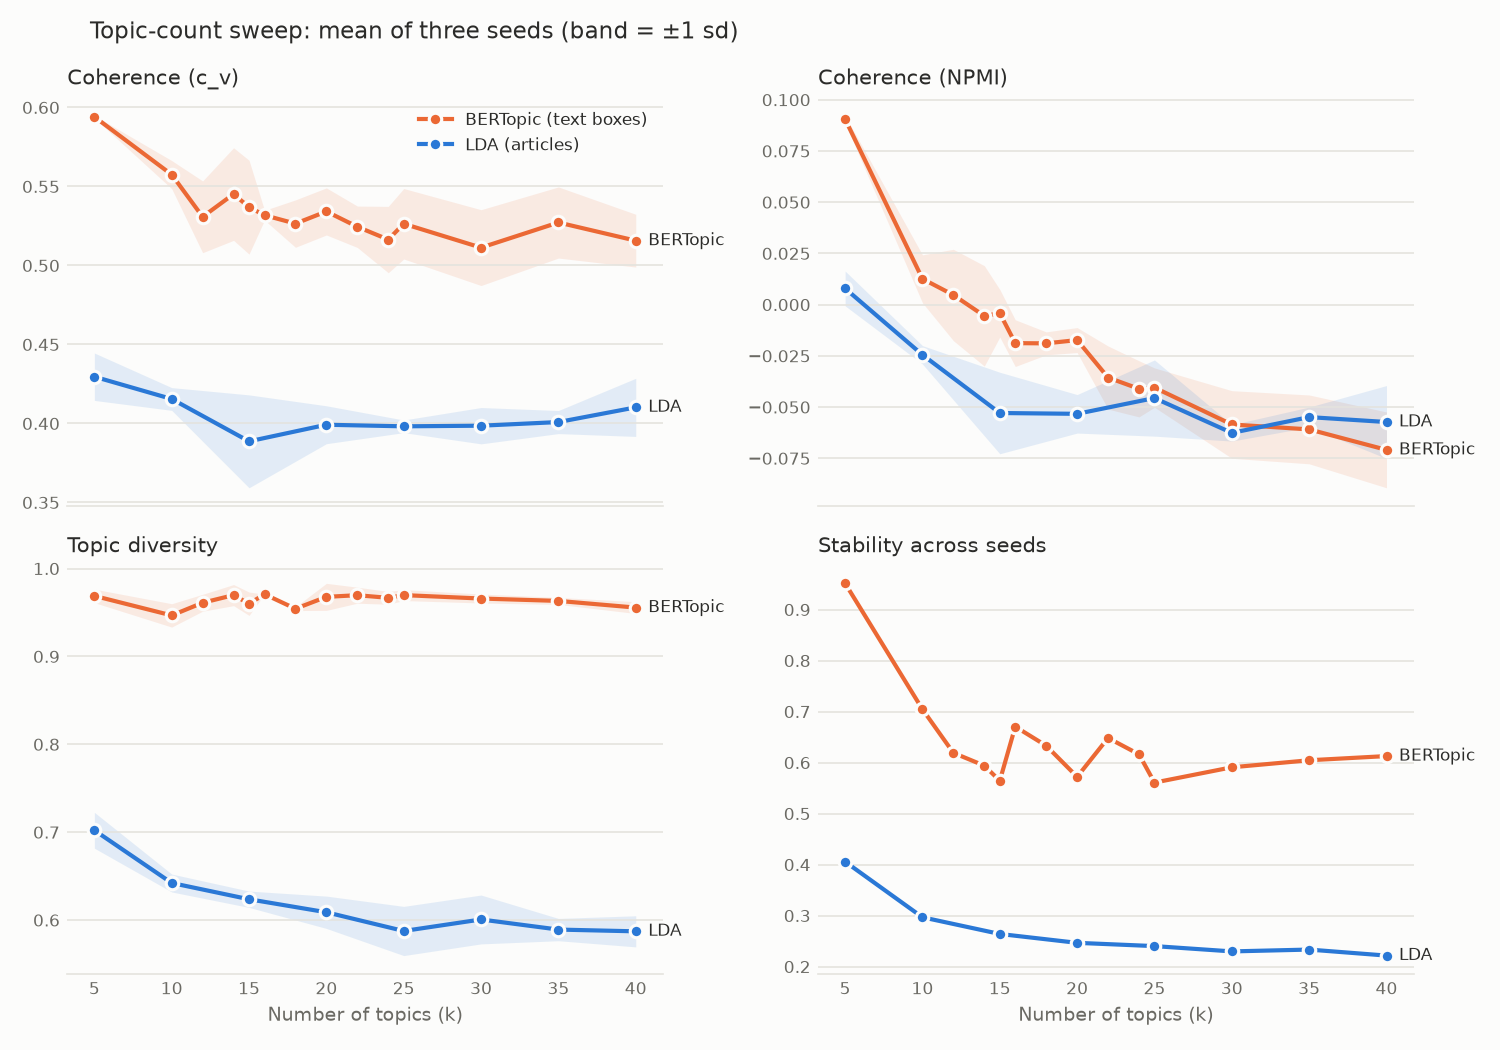

In [2]:
display(Image(str(SWEEPS / "sweep_scores.png")))

## The best counts by each score

For each model, the counts that rank in the top three on each score.

In [3]:
for m, g in summary.groupby("model"):
    print(m)
    for col in ["c_v", "c_npmi", "diversity", "stability"]:
        print(f"  {col:10s}", list(g.nlargest(3, col).k))

bertopic
  c_v        [5, 10, 14]
  c_npmi     [5, 10, 12]
  diversity  [16, 14, 25]
  stability  [5, 10, 16]
lda
  c_v        [5, 10, 40]
  c_npmi     [5, 10, 25]
  diversity  [5, 10, 15]
  stability  [5, 10, 15]


## Reading the topics

Set `K` to a candidate count. Each topic shows:
- its top words;
- the number of articles mainly about it;
- its share of all words;
- its top articles (with their weights).

Look for topics that mix two subjects (too few topics) and pairs of topics on
one subject (too many).

In [4]:
def show(model, k, articles=True):
    t = pd.read_csv(SWEEPS / model / f"topics_k{k}.csv")
    for r in t.itertuples():
        print(f"[{model} k={k}] topic {r.topic_id}: {r.n_articles_main} articles, {r.share_of_words:.1%} of words")
        print("   ", r.top_words)
        if articles and isinstance(r.top_articles, str):
            for a in r.top_articles.split(" || ")[:3]:
                print("     -", a)
    print()

K = 10
show("lda", K)
show("bertopic", K)

[lda k=10] topic 0: 22 articles, 5.0% of words
    feet timber river island miles generally like having head year form large stone water men
     - chambers_1843 p16: FAIRY RINGS IN PASTURE (1.00)
     - saturday_1834 p8: No. III. ON THE DISCOVERY OF MINERAL VEINS, AND THE MODE OF FIRST OPENING A MINE (1.00)
     - saturday_1840 p14: THE TIMBER-FLOATS OF GERMANY AND ITALY (1.00)
[lda k=10] topic 1: 28 articles, 4.1% of words
    good man day like paul know life did family young thor means nature called hole
     - chambers_1840 p17: "ADVENTURES OF ROBIN DAY." (1.00)
     - chambers_1843 p27: ON A MYSTERIOUS CIRCUMSTANCE CONNECTED WITH SCOTTISH GASTRONOMY (1.00)
     - chambers_1837 p31: THE FIRST DAY OF TERM (1.00)
[lda k=10] topic 2: 30 articles, 3.7% of words
    wax heat half language bread years richmond people present year having nature period use like
     - chambers_1843 p19: HOW TO LEARN LANGUAGES (1.00)
     - saturday_1840 p28: ON WAX FIGURES (1.00)
     - chambers_1840 p10: 

In [5]:
K = 20
show("lda", K)
show("bertopic", K)

[lda k=20] topic 0: 15 articles, 2.7% of words
    feet timber river grass generally form like soil year glass ring surface head circles near
     - chambers_1843 p16: FAIRY RINGS IN PASTURE (1.00)
     - saturday_1843 p7: THE FREEZING OF THE RIVER NEVA (1.00)
     - penny_1836 p10: ARTS OF ANCIENT EGYPT-GLASS AND PORCELAIN (1.00)
[lda k=20] topic 1: 14 articles, 1.9% of words
    thor hole land odin called gods god know greeks day earth powder colonies hammer stone
     - saturday_1843 p11: ON QUARRYING STONE (1.00)
     - penny_1843 p13: Usefulness of Moles (1.00)
     - penny_1844 p25: The Type of the Spaniards (1.00)
[lda k=20] topic 2: 24 articles, 2.7% of words
    heat half bread years richmond present year people country castle britain like period view weather
     - saturday_1837 p17: I. ON THE ANCIENT INHABITANTS OF EUROPE, AND… (1.00)
     - chambers_1840 p10: to SUPPOSED CHANGES IN THE WEATHER OF LATE YEARS (1.00)
     - saturday p15: ON BREAD (1.00)
[lda k=20] topic 3: 13 

## Topic sizes

Very small topics (one or two articles) at a count usually mean the count is
too high for this corpus, or that the topic is one odd group of texts (such as
the chess problems).

In [6]:
rows = []
for p in sorted(SWEEPS.glob("*/topics_k*.csv")):
    t = pd.read_csv(p)
    rows.append(dict(model=p.parent.name, k=int(p.stem.split("_k")[1]),
                     topics_under_3_articles=int((t.n_articles_main < 3).sum()),
                     largest_topic_share=t.share_of_words.max().round(3)))
pd.DataFrame(rows).sort_values(["model", "k"])

,model,k,topics_under_3_articles,largest_topic_share
13,bertopic,5,0,0.407
0,bertopic,10,0,0.214
1,bertopic,12,1,0.221
2,bertopic,14,1,0.146
3,bertopic,15,1,0.133
4,bertopic,16,1,0.176
5,bertopic,18,1,0.116
6,bertopic,20,1,0.127
7,bertopic,22,1,0.129
8,bertopic,24,2,0.108
